# Hypothesis 1: Warm and dry weather → higher croissant sales

**Purpose.** This notebook tests hypothesis 1 from canvas block 2: *on warm and dry days, the branch sells more croissants (product group 3)*. It is an exploration, not a model.

**Data.** Daily turnover of group 3 (2013-07-01 – 2018-07-31) and the observed weather in Kiel, from the course data.

**Definitions and decisions used here** (see `DECISIONS.md`, `GLOSSARY.md`):
- *Warm*: mean daily temperature (`Temperatur`, °C).
- *Dry / rainy*: from `Wettercode` (WMO code). **Rainy = code 50–99** (drizzle, rain, snow, showers, thunderstorm). **Missing code = dry** ("no notable weather"). The team does not use `Wettercode` in models; using it here is an exception for this exploration only.
- Days without a weather row are filled with the previous day's weather (forward fill).
- Only days with croissant sales are used (left join, sales as the base).

**Main pitfall: season.** Warm days are mostly summer days, and in summer Kiel has more visitors anyway. So we first look at the raw relationship, then compare each day only with days of the **same month and the same weekday**, to separate "warm" from "summer" and "weekend".

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

BASE_URL = "https://raw.githubusercontent.com/opencampus-sh/intro-to-data-science-and-ml/main/data/bakery/"
WEEKDAYS = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

# Chart colours: fixed categorical order (slot 1 = dry, slot 2 = rainy)
COLORS = {"dry": "#2a78d6", "rainy": "#eb6834"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": True, "grid.alpha": 0.3, "figure.dpi": 110})

sales = pd.read_csv(BASE_URL + "umsatzdaten_gekuerzt.csv", parse_dates=["Datum"])
weather = pd.read_csv(BASE_URL + "wetter.csv", parse_dates=["Datum"])
print("sales:", sales.shape, " weather:", weather.shape)

sales: (9334, 4)  weather: (2601, 5)


## 1. Prepare the data

**Step 1 – fill missing weather days.** The weather file has no row for some days. We add those days and copy the previous day's values (*forward fill*: only the past is used, so no information from the future leaks in).

**Step 2 – rain flag.** A day is *rainy* if its weather code is between 50 and 99; otherwise (code below 50, or no code) it is *dry*.

**Step 3 – join.** Keep only croissant rows (group 3) and attach the weather by date (*left join*). The number of rows must not change.

In [2]:
# Step 1: full calendar, forward fill only the days that had no weather row
w = weather.set_index("Datum").sort_index()
calendar = pd.date_range(w.index.min(), w.index.max(), freq="D")
added = calendar.difference(w.index)
w = w.reindex(calendar)
w.loc[added] = w.ffill().loc[added]          # whole row copied from the previous day
w["Bewoelkung"] = w["Bewoelkung"].ffill()     # 10 single missing cloud-cover values
w.index.name = "Datum"

# Step 2: rain flag (code 50–99 = precipitation; missing code = no notable weather = dry)
w["rainy"] = w["Wettercode"].between(50, 99)
w["weather_type"] = np.where(w["rainy"], "rainy", "dry")

# Step 3: croissants (group 3) + weather
croissant = sales[sales["Warengruppe"] == 3][["Datum", "Umsatz"]]
df = croissant.merge(w.reset_index()[["Datum", "Temperatur", "Bewoelkung", "Wettercode", "weather_type"]],
                     on="Datum", how="left")

# Checks: row count unchanged, no missing weather after the fill
assert len(df) == len(croissant) == 1819, len(df)
assert df[["Temperatur", "weather_type"]].notna().all().all()
print("weather days added by forward fill:", len(added))
print("croissant days:", len(df))
print(df["weather_type"].value_counts())

weather days added by forward fill: 169
croissant days: 1819
weather_type
dry      1173
rainy     646
Name: count, dtype: int64


## 2. Overview

How are temperature and croissant turnover distributed, and how many dry and rainy days do we have?

       Umsatz  Temperatur
count  1819.0      1819.0
mean    163.3        12.2
std      75.6         7.3
min      37.7        -8.5
25%     105.6         6.4
50%     142.8        12.1
75%     202.0        18.1
max     565.9        31.4

             Temperatur              Umsatz              
                  count  mean median  count   mean median
weather_type                                             
dry                1173  13.1   13.8   1173  169.2  151.1
rainy               646  10.5    9.8    646  152.7  132.3


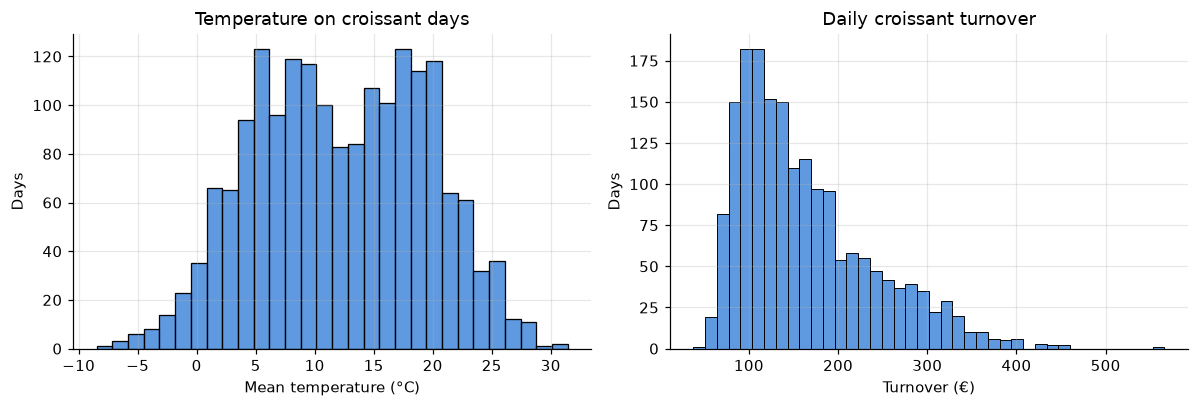

In [3]:
print(df[["Umsatz", "Temperatur"]].describe().round(1))
print()
print(df.groupby("weather_type")[["Temperatur", "Umsatz"]].agg(["count", "mean", "median"]).round(1))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
sns.histplot(df["Temperatur"], bins=30, ax=axes[0], color=COLORS["dry"])
axes[0].set(title="Temperature on croissant days", xlabel="Mean temperature (°C)", ylabel="Days")
sns.histplot(df["Umsatz"], bins=40, ax=axes[1], color=COLORS["dry"])
axes[1].set(title="Daily croissant turnover", xlabel="Turnover (€)", ylabel="Days")
plt.tight_layout(); plt.show()

## 3. Raw relationship: turnover by temperature band, dry vs. rainy

Each bar is the **average croissant turnover** of all days in that temperature band. The black line on each bar is the **95 % confidence interval**: the range in which the true average lies with high probability. Short line = many days and a reliable average; long line = few days.

*Caution:* this view still mixes temperature with season (see section 4).

Days per band and weather type:
weather_type  dry  rainy
temp_band               
< 0            46     17
0–5           153    115
5–10          221    198
10–15         210    147
15–20         293    126
20–25         197     39
≥ 25           53      4


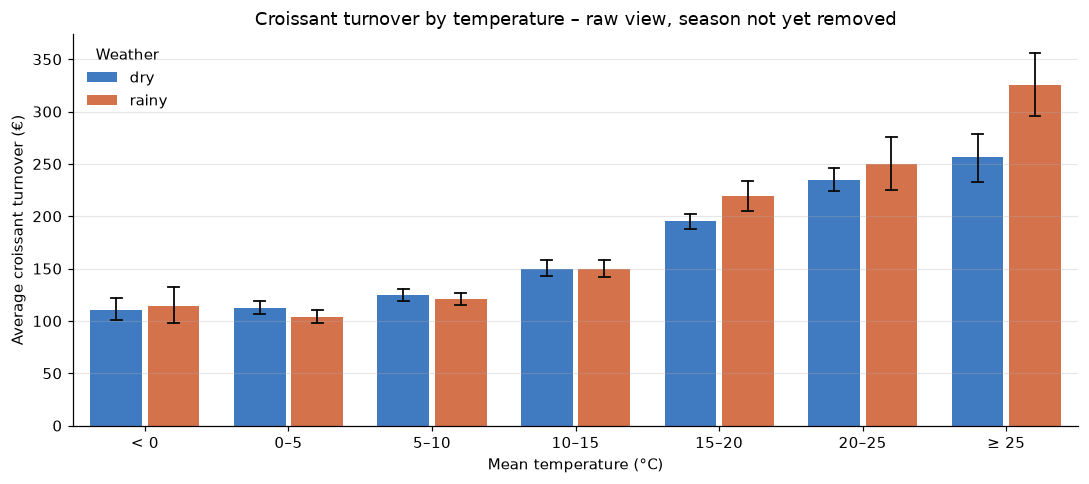

In [4]:
bins = [-np.inf, 0, 5, 10, 15, 20, 25, np.inf]
labels = ["< 0", "0–5", "5–10", "10–15", "15–20", "20–25", "≥ 25"]
df["temp_band"] = pd.cut(df["Temperatur"], bins=bins, labels=labels, right=False)

print("Days per band and weather type:")
print(pd.crosstab(df["temp_band"], df["weather_type"]))

fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=df, x="temp_band", y="Umsatz", hue="weather_type", hue_order=["dry", "rainy"],
            palette=COLORS, errorbar=("ci", 95), err_kws={"color": "#0b0b0b", "linewidth": 1.2},
            capsize=0.15, gap=0.1, ax=ax)
ax.set(title="Croissant turnover by temperature – raw view, season not yet removed",
       xlabel="Mean temperature (°C)", ylabel="Average croissant turnover (€)")
ax.legend(title="Weather", frameon=False)
plt.tight_layout(); plt.show()

In [5]:
rho, p = stats.spearmanr(df["Temperatur"], df["Umsatz"])
print(f"Spearman correlation temperature vs. turnover (raw): rho = {rho:.2f}, p = {p:.1e}")
print("Mean turnover: dry", round(df.loc[df.weather_type == "dry", "Umsatz"].mean(), 1),
      "| rainy", round(df.loc[df.weather_type == "rainy", "Umsatz"].mean(), 1))
print()
print("Mean turnover (€) per temperature band:")
print(df.groupby("temp_band", observed=True)["Umsatz"].mean().round(1))
print()
print("Mean turnover (€) per temperature band and weather type:")
print(df.groupby(["temp_band", "weather_type"], observed=True)["Umsatz"].mean().unstack().round(1))

Spearman correlation temperature vs. turnover (raw): rho = 0.65, p = 2.8e-219
Mean turnover: dry 169.2 | rainy 152.7

Mean turnover (€) per temperature band:
temp_band
< 0      111.7
0–5      109.0
5–10     123.1
10–15    150.0
15–20    202.5
20–25    237.3
≥ 25     261.3
Name: Umsatz, dtype: float64

Mean turnover (€) per temperature band and weather type:
weather_type    dry  rainy
temp_band                 
< 0           110.7  114.4
0–5           112.8  103.9
5–10          124.8  121.2
10–15         150.0  150.1
15–20         195.2  219.5
20–25         234.8  250.0
≥ 25          256.5  325.2


## 4. Remove season and weekday

Warm days are mostly in summer, and summer (tourists, Kiel Week, holidays) may raise sales regardless of weather. Weekends differ too.

To separate these, we compare each day only with its "neighbours":
- **Relative turnover** = turnover of the day ÷ median turnover of days in the **same month of the same year on the same weekday**. A value of 1.10 means "10 % more than a typical comparable day".
- **Temperature anomaly** = temperature of the day − mean temperature of that month. A value of +3 means "3 °C warmer than usual for that month".

If warm weather itself drives croissant sales, relative turnover should still rise with the temperature anomaly.

In [6]:
df["year_month"] = df["Datum"].dt.to_period("M")
df["weekday"] = pd.Categorical(df["Datum"].dt.day_name(), categories=WEEKDAYS, ordered=True)

df["rel_turnover"] = df["Umsatz"] / df.groupby(["year_month", "weekday"], observed=True)["Umsatz"].transform("median")
df["temp_anomaly"] = df["Temperatur"] - df.groupby("year_month")["Temperatur"].transform("mean")

print("Months:", df["year_month"].nunique(),
      "| summers (Jun–Aug) in data:", df.loc[df.Datum.dt.month.isin([6, 7, 8]), "Datum"].dt.year.nunique())

rho_a, p_a = stats.spearmanr(df["temp_anomaly"], df["rel_turnover"])
print(f"Spearman correlation temperature anomaly vs. relative turnover: rho = {rho_a:.2f}, p = {p_a:.1e}")

abins = [-np.inf, -4, -2, 0, 2, 4, np.inf]
alabels = ["< −4", "−4 to −2", "−2 to 0", "0 to 2", "2 to 4", "> 4"]
df["anom_band"] = pd.cut(df["temp_anomaly"], bins=abins, labels=alabels, right=False)
print()
print("Days per band and weather type:")
print(pd.crosstab(df["anom_band"], df["weather_type"]))
print()
print("Mean relative turnover per anomaly band:")
print(df.groupby("anom_band", observed=True)["rel_turnover"].mean().round(3))

Months: 61 | summers (Jun–Aug) in data: 6
Spearman correlation temperature anomaly vs. relative turnover: rho = 0.13, p = 1.5e-08

Days per band and weather type:
weather_type  dry  rainy
anom_band               
< −4           91     56
−4 to −2      172    133
−2 to 0       299    190
0 to 2        304    139
2 to 4        182     84
> 4           125     44

Mean relative turnover per anomaly band:
anom_band
< −4        1.026
−4 to −2    0.996
−2 to 0     1.014
0 to 2      1.020
2 to 4      1.051
> 4         1.066
Name: rel_turnover, dtype: float64


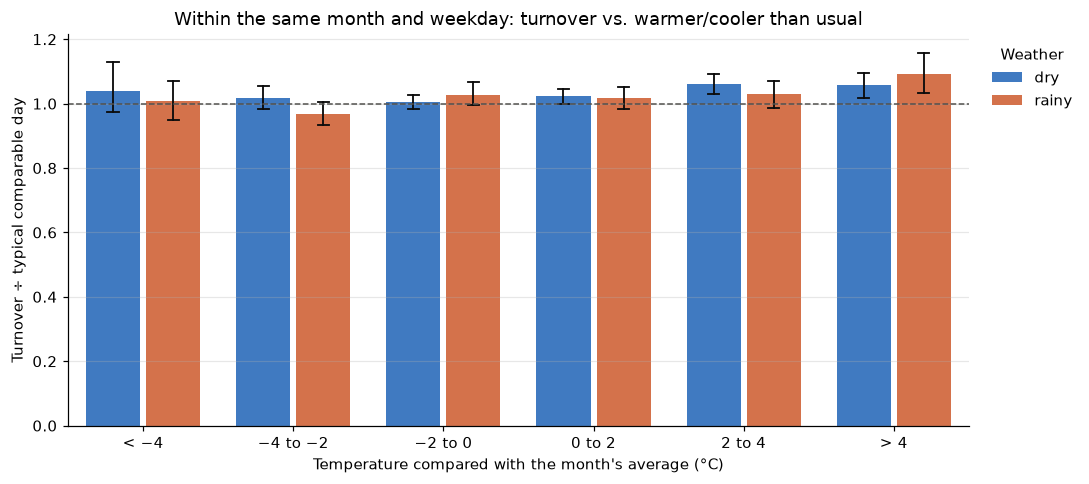

In [7]:
fig, ax = plt.subplots(figsize=(10, 4.5))
sns.barplot(data=df, x="anom_band", y="rel_turnover", hue="weather_type", hue_order=["dry", "rainy"],
            palette=COLORS, errorbar=("ci", 95), err_kws={"color": "#0b0b0b", "linewidth": 1.2},
            capsize=0.15, gap=0.1, ax=ax)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.set(title="Within the same month and weekday: turnover vs. warmer/cooler than usual",
       xlabel="Temperature compared with the month's average (°C)",
       ylabel="Turnover ÷ typical comparable day")
ax.legend(title="Weather", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

### Dry vs. rainy, season and weekday removed

Average relative turnover on dry and rainy days, with 95 % confidence interval, and the same split for summer (Jun–Aug) and the rest of the year.

                               days   mean  ci_low  ci_high
period           weather_type                              
rest of year     dry            835  1.039   1.023    1.055
                 rainy          499  1.012   0.992    1.031
summer (Jun–Aug) dry            338  1.002   0.982    1.022
                 rainy          147  1.029   0.992    1.065

All days – dry: 1.028, rainy: 1.015, difference 1.3 %-points, Mann-Whitney p = 4.0e-02


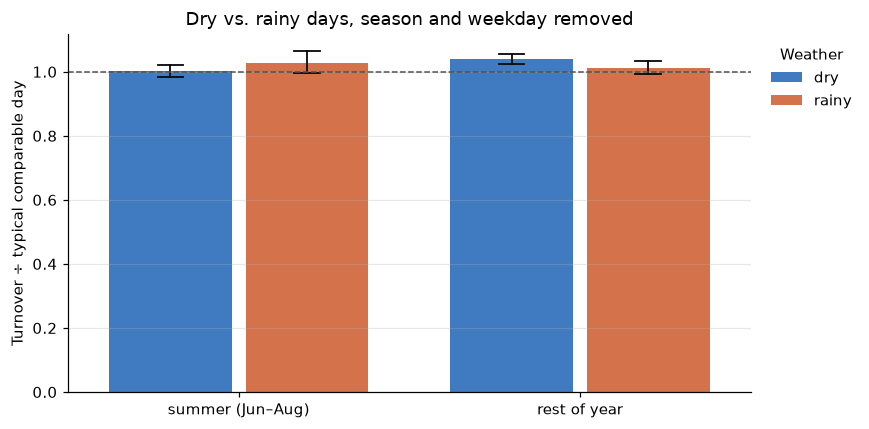

In [8]:
df["period"] = np.where(df["Datum"].dt.month.isin([6, 7, 8]), "summer (Jun–Aug)", "rest of year")

def ci95(x):
    return stats.t.interval(0.95, len(x) - 1, loc=x.mean(), scale=stats.sem(x))

summary = (df.groupby(["period", "weather_type"])["rel_turnover"]
             .agg(days="count", mean="mean",
                  ci_low=lambda x: ci95(x)[0], ci_high=lambda x: ci95(x)[1])
             .round(3))
print(summary)

dry = df.loc[df.weather_type == "dry", "rel_turnover"]
rainy = df.loc[df.weather_type == "rainy", "rel_turnover"]
u, p_u = stats.mannwhitneyu(dry, rainy)
print(f"\nAll days – dry: {dry.mean():.3f}, rainy: {rainy.mean():.3f}, "
      f"difference {100 * (dry.mean() - rainy.mean()):.1f} %-points, Mann-Whitney p = {p_u:.1e}")

fig, ax = plt.subplots(figsize=(8, 4))
sns.barplot(data=df, x="period", y="rel_turnover", hue="weather_type", hue_order=["dry", "rainy"],
            order=["summer (Jun–Aug)", "rest of year"], palette=COLORS, errorbar=("ci", 95),
            err_kws={"color": "#0b0b0b", "linewidth": 1.2}, capsize=0.15, gap=0.1, ax=ax)
ax.axhline(1, color="#52514e", linewidth=1, linestyle="--")
ax.set(title="Dry vs. rainy days, season and weekday removed", xlabel="",
       ylabel="Turnover ÷ typical comparable day")
ax.legend(title="Weather", frameon=False, loc="upper left", bbox_to_anchor=(1.01, 1))
plt.tight_layout(); plt.show()

## 5. Summary

**Verdict: partly supported. "Warm" matters, but much less than the raw numbers suggest; "dry" is not supported.**

**Warm → more croissants: yes, but mostly a season effect.**
- Raw view: average croissant turnover rises from about 109–112 € below 5 °C to 261 € at 25 °C and above (Spearman rho = 0.65).
- After removing season and weekday, the link is much weaker (rho = 0.13). Days more than 4 °C warmer than the month's average sell about 6.6 % more than a typical comparable day, while days around the month's average sell about 1–2 % more. (These relative values sit slightly above 1 even without any effect, because each day is divided by a median; compare the bands with each other, not with 1.)
- So most of the "warm" effect is really "summer". Season and weekday should be in any model; temperature adds a little on top.

**Dry → more croissants: not supported.**
- Dry days have a higher raw average (169 € vs. 153 €), but only because rainy days are colder on average (10.5 °C vs. 13.1 °C).
- At the same temperature, rainy days are **not** worse: from 15 °C up, rainy days even have higher averages (15–20 °C: 220 € vs. 195 €; ≥ 25 °C: 325 € vs. 257 €, but only 4 rainy days).
- After removing season and weekday, dry days are only 1.3 %-points above rainy days (p = 0.04), and in summer the order is reversed (dry 1.00 vs. rainy 1.03; the confidence intervals overlap).

**Limits.**
- Weather is measured, not forecast; in real use the effect will be slightly weaker.
- "Rainy" comes from one daily WMO code (50–99). Codes 20–29 ("rain in the last hour") count as dry, and a short summer shower on a hot day counts as rainy, which may explain the surprising summer result.
- The data covers only 6 summers (2013 and 2018 partly), and very hot rainy days are rare.
- The exploration uses all data 2013–2018, including the period that may later become validation data.
- Turnover in €, not pieces; sold-out days hide true demand.

**For the team.** Keep season and weekday as core features and consider temperature (or the temperature anomaly) as an extra one. A rain flag from `Wettercode` does not look worth reversing the team's decision for croissants.